In [9]:
from torchvision import datasets, transforms

train_dataset = datasets.CIFAR10(
    root="data",          # папка внутри проекта
    train=True,
    download=True,        # скачает, если ещё нет
    transform=transforms.ToTensor()
)

In [10]:
import torch
from matplotlib import pyplot as plt

# Классы CIFAR-10
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

In [11]:
# Достаём картинки и метки в переменные

images = torch.stack([img for img, _ in train_dataset])
labels = torch.tensor([label for _, label in train_dataset])

print("images:", images.shape, images.dtype)
print("labels:", labels.shape, labels.dtype)

images: torch.Size([50000, 3, 32, 32]) torch.float32
labels: torch.Size([50000]) torch.int64


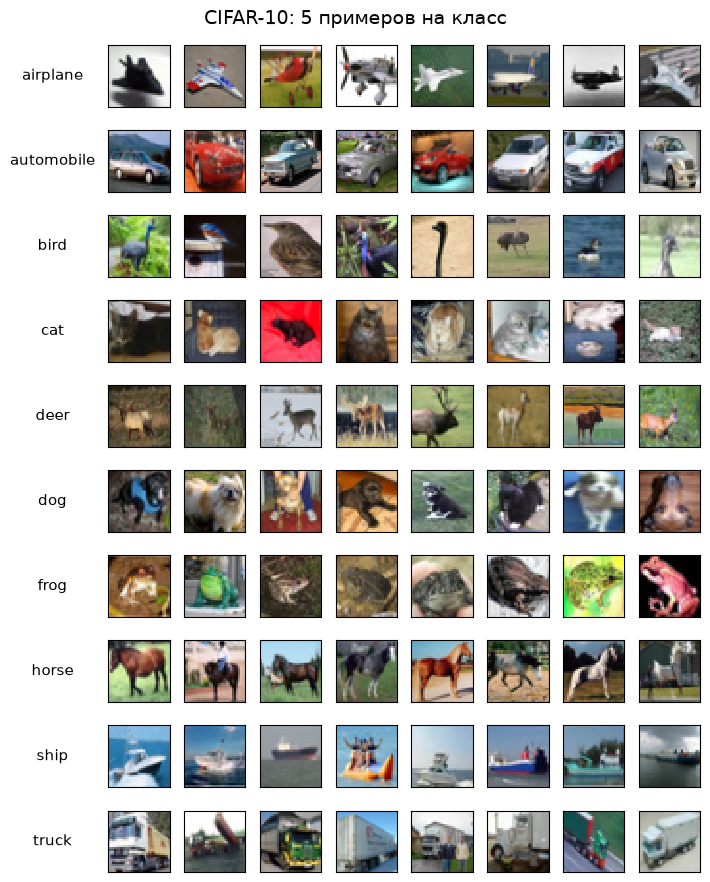

In [12]:
# По 5 примеров на каждый класс
samples_per_class = 8
cell = 0.9

fig, axes = plt.subplots(
    nrows=len(CLASSES),
    ncols=samples_per_class,
    figsize=(samples_per_class * cell, len(CLASSES) * cell)
)

for class_idx, class_name in enumerate(CLASSES):
    # индексы всех картинок этого класса
    idxs = (labels == class_idx).nonzero(as_tuple=True)[0]
    # первые 5
    chosen = idxs[:samples_per_class]

    for j, idx in enumerate(chosen):
        ax = axes[class_idx, j]
        img = images[idx]
        ax.imshow(img.permute(1, 2, 0).numpy(), interpolation='nearest')
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(class_name, fontsize=11, rotation=0,
                          labelpad=40, va='center')

plt.suptitle("CIFAR-10: 5 примеров на класс", fontsize=14)
plt.tight_layout()
plt.show()